# 03 Models: LightGBM on history, then history + text

- What it does: tunes LightGBM on the history features (M1), embeds the previous inspection's comments with a pre-trained BERT-style encoder, tunes LightGBM on history + text (M2), and compares the two on 2023.
- Inputs: `data/processed/model_table.parquet`, the baseline predictions in `preds/`.
- Outputs: `preds/M1_lgbm_val.csv`, `preds/M2_lgbm_text_val.csv`, `data/processed/embeddings.npy`, `results/validation_results.csv`, `results/validation_differences.csv`, `results/lgbm_grid_val.csv`, `results/feature_importance_val.csv`, `results/improvement_loop_val.csv`, `results/text_examples.md`, `results/selected_settings.json`, `results/figures/gains_curve_val.png`.

All tuning uses the validation year (2023). The test years (2024 onward) are not used anywhere in this notebook.

In [1]:
import sys
sys.path.insert(0, "..")

import json
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

from src import evaluate as E
from src import models as M
from src import text as T

SEED = 42
np.random.seed(SEED)
pd.set_option("display.width", 180)

In [2]:
table = M.load_model_table("../data/processed/model_table.parquet")
is_train = (table["split"] == "train").to_numpy()
is_val = (table["split"] == "val").to_numpy()
train, val = table[is_train], table[is_val]
y_val = val[M.TARGET].to_numpy()
val_groups = val["licenseno"].to_numpy()     # confidence intervals resample whole restaurants
print(f"train {len(train):,} rows | validation {len(val):,} rows")
print("history features:", M.HISTORY_FEATURES)

train 35,872 rows | validation 5,521 rows
history features: ['prior_n', 'prior_n_3y', 'is_first', 'prior_fail_rate', 'prior_routine_fail_rate', 'last_fail', 'last_n_viol', 'last_n_lvl3', 'last_routine_fail', 'last_routine_n_viol', 'last_routine_n_lvl3', 'days_since_last', 'license_age_days', 'month', 'is_takeout', 'neighborhood', 'zip']


## 1. M1: LightGBM on history features

A small grid of 12 combinations. Each fit stops early when the validation AUC stops improving, so `n_estimators` is an upper limit and `best_iteration` is the number of trees actually used. We keep the combination with the best validation hit rate (`precision_at_k`).

Every validation number in this project is somewhat optimistic. The same year picks the settings of M1 and M2 (the 12 combinations differ by less than one point), and the features and the baseline definitions were also refined while looking at 2023. Only the test numbers in notebook 04 count as performance.

In [3]:
print("grid:", M.LGBM_GRID)
grid_m1, params_m1 = M.grid_search_lgbm(train, val, M.HISTORY_FEATURES)
print("selected M1 settings:", params_m1)
grid_m1.round(4)

grid: {'num_leaves': [7, 15, 31], 'learning_rate': [0.02, 0.05], 'n_estimators': [100, 500]}


selected M1 settings: {'num_leaves': 31, 'learning_rate': 0.02, 'n_estimators': 231}


,num_leaves,learning_rate,n_estimators,best_iteration,auc,catch_at_k,precision_at_k,n
0,7,0.02,100,100,0.7768,0.3215,0.8967,5521
1,7,0.02,500,355,0.7838,0.3232,0.9013,5521
2,7,0.05,100,99,0.7826,0.3238,0.9031,5521
3,7,0.05,500,139,0.7834,0.3232,0.9013,5521
4,15,0.02,100,100,0.7782,0.3232,0.9013,5521
5,15,0.02,500,264,0.7818,0.3222,0.8986,5521
6,15,0.05,100,96,0.7816,0.3228,0.9004,5521
7,15,0.05,500,135,0.7821,0.3235,0.9022,5521
8,31,0.02,100,100,0.7780,0.3235,0.9022,5521
9,31,0.02,500,231,0.7803,0.3245,0.9049,5521


In [4]:
m1 = M.fit_lgbm(train, M.HISTORY_FEATURES, params_m1)
score_m1 = m1.predict_proba(val[M.HISTORY_FEATURES])[:, 1]
M.save_preds(val, score_m1, "../preds/M1_lgbm_val.csv")

importance_m1 = M.importance_table(m1, M.HISTORY_FEATURES, top=15)
importance_m1.round(3)

,feature,gain,share_of_gain
0,last_routine_n_viol,110859.302,0.405
1,prior_routine_fail_rate,43717.347,0.160
2,zip,30355.174,0.111
3,prior_fail_rate,24777.641,0.091
4,last_fail,18121.202,0.066
5,days_since_last,13649.685,0.050
6,license_age_days,10784.622,0.039
7,month,6825.387,0.025
8,prior_n,4991.220,0.018
9,prior_n_3y,4987.108,0.018


## 2. Text: embed the previous inspection's comments

The text for each inspection is `prior_comments`: what the inspector wrote at the **previous** visit. Comments from the inspection being predicted are never used.

The encoder is `sentence-transformers/all-MiniLM-L6-v2`, used frozen (no training). Each comment becomes the average of its token vectors (mean pooling over the attention mask), a vector of 384 numbers. Comments are cut at 256 tokens.

First we time 100 comments to estimate the full run.

In [5]:
has_text = (table["prior_comments"].str.strip() != "").to_numpy()
n_unique = table.loc[has_text, "prior_comments"].nunique()
sample = table.loc[has_text, "prior_comments"].sample(100, random_state=SEED).tolist()

T.embed_texts(sample[:8], verbose=False)      # warm-up, so the timing excludes loading the model
started = time.time()
T.embed_texts(sample, verbose=False)
seconds_per_100 = time.time() - started
print(f"device: {T.get_device()} | 100 comments in {seconds_per_100:.2f}s | "
      f"estimated full run for {n_unique:,} unique comments: {seconds_per_100 / 100 * n_unique / 60:.1f} minutes")

W1111 17:43:42.713000 79251 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

device: mps | 100 comments in 0.27s | estimated full run for 39,356 unique comments: 1.7 minutes


In [6]:
# Cached: the second run of this notebook loads the file instead of embedding again.
embeddings = T.embed_cached(table["inspection_id"], table["prior_comments"], cache_dir="../data/processed")
print("embeddings:", embeddings.shape, "| rows with comments:", int(has_text.sum()),
      "| rows without (zero vector):", int((~has_text).sum()))

Loaded cached embeddings: ../data/processed/embeddings.npy
embeddings: (58564, 384) | rows with comments: 40379 | rows without (zero vector): 18185


### PCA to 32 dimensions, fitted on training rows only

384 text columns would swamp the history features, so we compress them to 32 principal components. The PCA is fitted on training rows that have comments, then applied to every row.

In [7]:
pca = T.fit_pca(embeddings, fit_mask=is_train & has_text)
print(f"variance kept by 32 components: {pca.explained_variance_ratio_.sum():.1%}")

table_text = T.add_text_features(table, embeddings, pca)
train_t, val_t = table_text[is_train], table_text[is_val]
FEATURES_M2 = M.HISTORY_FEATURES + T.TEXT_FEATURES
print(len(FEATURES_M2), "features for M2")

variance kept by 32 components: 59.8%
50 features for M2


## 3. M2: LightGBM on history + text

Same grid, same selection rule.

In [8]:
grid_m2, params_m2 = M.grid_search_lgbm(train_t, val_t, FEATURES_M2)
print("selected M2 settings:", params_m2)
grid_m2.round(4)

selected M2 settings: {'num_leaves': 7, 'learning_rate': 0.05, 'n_estimators': 100}


,num_leaves,learning_rate,n_estimators,best_iteration,auc,catch_at_k,precision_at_k,n
0,7,0.02,100,100,0.7777,0.3215,0.8967,5521
1,7,0.02,500,457,0.7845,0.3238,0.9031,5521
2,7,0.05,100,100,0.7834,0.3248,0.9058,5521
3,7,0.05,500,229,0.7850,0.3241,0.9040,5521
4,15,0.02,100,100,0.7797,0.3232,0.9013,5521
5,15,0.02,500,344,0.7832,0.3248,0.9058,5521
6,15,0.05,100,95,0.7830,0.3232,0.9013,5521
7,15,0.05,500,106,0.7830,0.3232,0.9013,5521
8,31,0.02,100,100,0.7793,0.3238,0.9031,5521
9,31,0.02,500,262,0.7812,0.3225,0.8995,5521


In [9]:
m2 = M.fit_lgbm(train_t, FEATURES_M2, params_m2)
score_m2 = m2.predict_proba(val_t[FEATURES_M2])[:, 1]
M.save_preds(val, score_m2, "../preds/M2_lgbm_text_val.csv")

importance_m2 = M.importance_table(m2, FEATURES_M2, top=15)
pd.concat([grid_m1.assign(model="M1_lgbm"), grid_m2.assign(model="M2_lgbm_text")]).to_csv(
    "../results/lgbm_grid_val.csv", index=False)
pd.concat([importance_m1.assign(model="M1_lgbm"), importance_m2.assign(model="M2_lgbm_text")]).to_csv(
    "../results/feature_importance_val.csv", index=False)
importance_m2.round(3)

,feature,gain,share_of_gain
0,last_routine_n_viol,36880.665,0.393
1,prior_routine_fail_rate,19162.202,0.204
2,prior_fail_rate,10524.416,0.112
3,zip,7994.065,0.085
4,last_fail,7144.395,0.076
5,days_since_last,1831.895,0.020
6,license_age_days,1615.703,0.017
7,month,1499.648,0.016
8,text_pc18,1278.633,0.014
9,neighborhood,1132.587,0.012


## 4. Does text add value? (ablation on validation)

M1 and M2 differ in the text features and in their tuned settings. The second comparison below removes the settings from the picture: it gives M1's settings to a model with the text features.

Confidence intervals come from 2,000 bootstrap resamples of whole restaurants. For a difference, both models are scored on the same resamples.

In [10]:
ablation = E.results_table(y_val, {"M1_lgbm": score_m1, "M2_lgbm_text": score_m2}, groups=val_groups)
print(ablation.round(3).to_string(index=False))

print("\nM2 minus M1, each with its own tuned settings (95% CI):")
text_effect = E.paired_differences(y_val, score_m2, score_m1, groups=val_groups)
for metric, (diff, lo, hi) in text_effect.items():
    print(f"  {metric:15s} {diff:+.3f}  [{lo:+.3f}, {hi:+.3f}]")

m1_plus_text = M.fit_lgbm(train_t, FEATURES_M2, params_m1)
same = E.paired_differences(y_val, m1_plus_text.predict_proba(val_t[FEATURES_M2])[:, 1], score_m1, groups=val_groups)
d, l, h = same["precision_at_k"]
print(f"\nSame settings as M1, text features added: hit rate {d * 100:+.1f} points (95% CI {l * 100:+.1f} to {h * 100:+.1f})")

diff, lo, hi = text_effect["precision_at_k"]
if lo > 0:
    sentence = (f"Adding the previous inspection's comments raises the validation hit rate by {diff * 100:.1f} points "
                f"(95% CI {lo * 100:+.1f} to {hi * 100:+.1f}), more than sampling noise.")
elif hi < 0:
    sentence = (f"Adding the previous inspection's comments lowers the validation hit rate by {-diff * 100:.1f} points "
                f"(95% CI {lo * 100:+.1f} to {hi * 100:+.1f}).")
else:
    sentence = (f"Adding the previous inspection's comments changes the validation hit rate by {diff * 100:+.1f} points "
                f"(95% CI {lo * 100:+.1f} to {hi * 100:+.1f}), which is within sampling noise: "
                f"on this data the text adds no measurable value beyond the history features.")
print("\n" + sentence)

       model   auc  catch_at_k  precision_at_k    n  auc_lo  auc_hi  catch_at_k_lo  catch_at_k_hi  precision_at_k_lo  precision_at_k_hi
     M1_lgbm 0.780       0.324           0.905 5521   0.767   0.793          0.316          0.333              0.884              0.924
M2_lgbm_text 0.783       0.325           0.906 5521   0.771   0.796          0.316          0.333              0.883              0.923

M2 minus M1, each with its own tuned settings (95% CI):


  auc             +0.003  [-0.000, +0.006]
  catch_at_k      +0.000  [-0.004, +0.004]
  precision_at_k  +0.001  [-0.012, +0.010]



Same settings as M1, text features added: hit rate -0.3 points (95% CI -1.1 to +0.5)

Adding the previous inspection's comments changes the validation hit rate by +0.1 points (95% CI -1.2 to +1.0), which is within sampling noise: on this data the text adds no measurable value beyond the history features.


## 5. Where the two models disagree most

The brief asks for failed validation inspections that M2 placed in its riskiest 10% and M1 ranked much lower. With the routine-only history features in M1 there are no such cases: the text moves rankings very little. The cell below measures that and saves the three largest moves.

In [11]:
examples = val[["inspection_id", "neighborhood", "prior_comments", M.TARGET]].copy()
examples["m1_percentile"] = pd.Series(score_m1, index=val.index).rank(pct=True)
examples["m2_percentile"] = pd.Series(score_m2, index=val.index).rank(pct=True)
candidates = (examples[(examples[M.TARGET] == 1) & (examples["m2_percentile"] >= 0.90)]
              .assign(jump=lambda d: d["m2_percentile"] - d["m1_percentile"]))
picked = candidates.sort_values("jump", ascending=False).head(3)

n_top = int(round(E.K * len(val)))                 # the same capacity as evaluate()
top_m1 = set(pd.Series(score_m1, index=val.index).nlargest(n_top).index)
top_m2 = set(pd.Series(score_m2, index=val.index).nlargest(n_top).index)
n_already = len(set(picked.index) & top_m1)

lines = ["# Where the text model and the history model disagree most",
         "",
         f"Validation year (2023). The text changes the ranking very little. Among the {len(candidates)} failed "
         f"inspections in the text model's riskiest 10%, the largest move up from the history-only ranking is "
         f"{candidates['jump'].max() * 100:.1f} percentile points and the median move is "
         f"{candidates['jump'].median() * 100:.1f}. The two models' riskiest-20% lists share "
         f"{len(top_m1 & top_m2):,} of {len(top_m1):,} inspections.",
         "",
         f"The three largest moves are below. {n_already} of the 3 were already in the history-only model's "
         f"riskiest 20%, so the text did not change the decision to visit them. The snippet is the inspector's "
         f"comment from the previous visit, the only text the model sees. Personal details are masked.",
         ""]
for i, row in enumerate(picked.itertuples(), 1):
    snippet = " ".join(row.prior_comments.split())[:400]
    lines += [f"## Example {i} ({row.neighborhood})",
              "",
              f"- History-only model (M1): riskier than {row.m1_percentile:.0%} of inspections",
              f"- History + text model (M2): riskier than {row.m2_percentile:.0%} of inspections",
              "",
              f"> {snippet}...",
              ""]
open("../results/text_examples.md", "w").write("\n".join(lines))
print("\n".join(lines))

# Where the text model and the history model disagree most

Validation year (2023). The text changes the ranking very little. Among the 526 failed inspections in the text model's riskiest 10%, the largest move up from the history-only ranking is 10.6 percentile points and the median move is 0.3. The two models' riskiest-20% lists share 1,004 of 1,104 inspections.

The three largest moves are below. 3 of the 3 were already in the history-only model's riskiest 20%, so the text did not change the decision to visit them. The snippet is the inspector's comment from the previous visit, the only text the model sees. Personal details are masked.

## Example 1 (Hyde Park)

- History-only model (M1): riskier than 80% of inspections
- History + text model (M2): riskier than 91% of inspections

> Allergen certification for person in charge expired provide current certification. | Provide current parasite destruction letter from sushi fish proveer. | Clean sides inbetween cooking equipment to remov

## 6. Improvement loop (one round)

An independent error analysis of the validation year proposed one change: two features that remember routine violations further back (`r3_mean_viol`, `prev2_routine_n_viol`).

The rule, fixed in advance: keep a change only if the validation hit rate improves by more than the half-width of M1's bootstrap confidence interval. One round only, because more rounds would overfit the validation year.

In [12]:
from src import features as F

full = pd.read_parquet("../data/processed/inspections_full.parquet")
full = full[full["date"] < "2024-01-01"]          # the test years are not needed here
CANDIDATES = ["r3_mean_viol", "prev2_routine_n_viol"]
table_cand = table.merge(F.candidate_memory_features(full), on="inspection_id", how="left")
assert (table_cand["inspection_id"].to_numpy() == table["inspection_id"].to_numpy()).all()
train_c, val_c = table_cand[is_train], table_cand[is_val]

m1_cand = M.fit_lgbm(train_c, M.HISTORY_FEATURES + CANDIDATES, params_m1)     # same settings as M1
score_cand = m1_cand.predict_proba(val_c[M.HISTORY_FEATURES + CANDIDATES])[:, 1]

base, cand = E.evaluate(y_val, score_m1), E.evaluate(y_val, score_cand)
ci_lo, ci_hi = E.bootstrap_ci(y_val, score_m1, "precision_at_k", groups=val_groups)
half_width = (ci_hi - ci_lo) / 2
gain = cand["precision_at_k"] - base["precision_at_k"]
d_lo, d_hi = E.bootstrap_diff_ci(y_val, score_cand, score_m1, "precision_at_k", groups=val_groups)
keep = gain > half_width

improvement = pd.DataFrame([{
    "idea": "routine-violation memory (r3_mean_viol, prev2_routine_n_viol)",
    "precision_at_k_before": base["precision_at_k"], "precision_at_k_after": cand["precision_at_k"],
    "gain": gain, "gain_ci_lo": d_lo, "gain_ci_hi": d_hi,
    "auc_before": base["auc"], "auc_after": cand["auc"],
    "threshold_ci_half_width": half_width, "kept": bool(keep), "n_val": len(y_val),
}])
improvement.to_csv("../results/improvement_loop_val.csv", index=False)
print(f"hit rate {base['precision_at_k']:.4f} -> {cand['precision_at_k']:.4f} (gain {gain * 100:+.2f} points, "
      f"95% CI {d_lo * 100:+.2f} to {d_hi * 100:+.2f})")
print(f"threshold (CI half-width of M1's hit rate): {half_width * 100:.2f} points -> "
      f"{'KEEP' if keep else 'NOT KEPT: the gain is smaller than the threshold'}")
assert not keep, "the candidate passed the rule: add it to models.NUM_FEATURES and features.add_history_features"

hit rate 0.9049 -> 0.9130 (gain +0.82 points, 95% CI -0.27 to +1.89)
threshold (CI half-width of M1's hit rate): 2.00 points -> NOT KEPT: the gain is smaller than the threshold


## 7. All five models on validation

In [13]:
val_scores = {name: pd.read_csv(f"../preds/{name}_val.csv")["score"].to_numpy()
              for name in ["B0_random", "B1_past_fail_rate", "B2_logreg"]}
val_scores["M1_lgbm"] = score_m1
val_scores["M2_lgbm_text"] = score_m2

validation_results = E.results_table(y_val, val_scores, groups=val_groups)
validation_results.to_csv("../results/validation_results.csv", index=False)
validation_results.round(3)

,model,auc,catch_at_k,precision_at_k,n,auc_lo,auc_hi,catch_at_k_lo,catch_at_k_hi,precision_at_k_lo,precision_at_k_hi
0,B0_random,0.500,0.200,0.558,5521,0.500,0.500,0.200,0.200,0.543,0.572
1,B1_past_fail_rate,0.717,0.288,0.804,5521,0.702,0.730,0.279,0.297,0.777,0.829
2,B2_logreg,0.776,0.319,0.889,5521,0.762,0.789,0.310,0.328,0.867,0.910
3,M1_lgbm,0.780,0.324,0.905,5521,0.767,0.793,0.316,0.333,0.884,0.924
4,M2_lgbm_text,0.783,0.325,0.906,5521,0.771,0.796,0.316,0.333,0.883,0.923


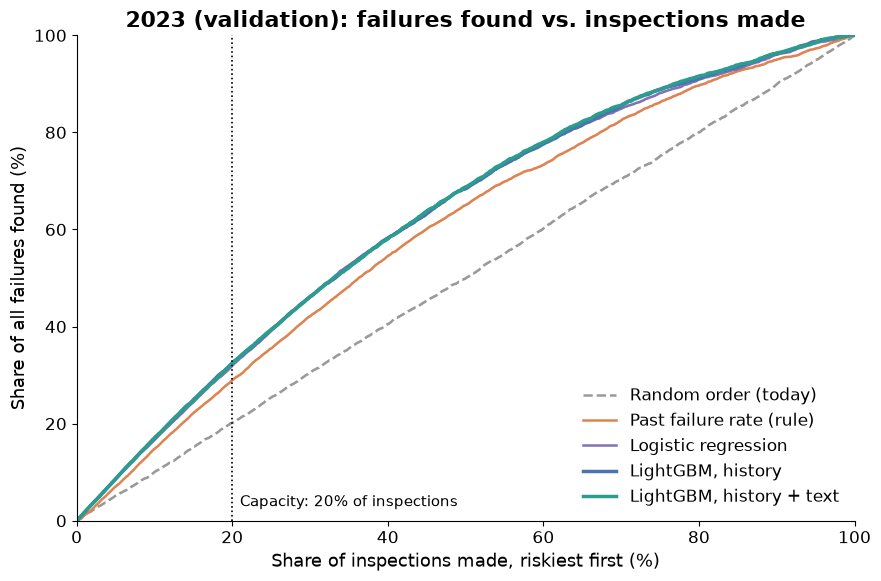

In [14]:
fig = E.plot_gains(y_val, val_scores, "2023 (validation): failures found vs. inspections made",
                   path="../results/figures/gains_curve_val.png")
plt.show()

### Which model do we carry forward?

The project brief names M1 (LightGBM on history features) as the main model and M2 as its text extension. The rule, applied here on validation before the test years are scored: keep M1 unless M2 beats it by more than sampling noise. A more elaborate model has to earn its place.

The table also compares M1 with the two baselines, so the reader can see how much of M1's performance a simpler approach already delivers.

In [15]:
text_wins = E.paired_differences(y_val, val_scores["M2_lgbm_text"], val_scores["M1_lgbm"], groups=val_groups)["precision_at_k"][1] > 0
FINAL = "M2_lgbm_text" if text_wins else "M1_lgbm"

val_differences = E.difference_table(y_val, val_scores, FINAL,
                                     [m for m in ["B1_past_fail_rate", "B2_logreg", "M1_lgbm", "M2_lgbm_text"] if m != FINAL],
                                     groups=val_groups)
val_differences.to_csv("../results/validation_differences.csv", index=False)
print(val_differences[val_differences["metric"] == "precision_at_k"].round(4).to_string(index=False))

vs_logreg = val_differences.query("minus == 'B2_logreg' and metric == 'precision_at_k'").iloc[0]
print(f"\nModel carried forward: {FINAL} ({E.MODEL_LABELS[FINAL]})")
print(f"Its lead over logistic regression is {vs_logreg['difference'] * 100:+.1f} points of hit rate "
      f"(95% CI {vs_logreg['ci_lo'] * 100:+.1f} to {vs_logreg['ci_hi'] * 100:+.1f}): "
      + ("larger than sampling noise." if vs_logreg["beyond_noise"] else
         "NOT distinguishable from sampling noise. On validation, logistic regression does as well."))

  model             minus         metric  difference   ci_lo  ci_hi  beyond_noise
M1_lgbm B1_past_fail_rate precision_at_k      0.1011  0.0777 0.1216          True
M1_lgbm         B2_logreg precision_at_k      0.0154  0.0000 0.0290         False
M1_lgbm      M2_lgbm_text precision_at_k     -0.0009 -0.0099 0.0117         False

Model carried forward: M1_lgbm (LightGBM, history)
Its lead over logistic regression is +1.5 points of hit rate (95% CI +0.0 to +2.9): NOT distinguishable from sampling noise. On validation, logistic regression does as well.


How to read this:

- M1 is carried forward unless the text model beats it beyond noise (see the printed line above).
- M1 clearly beats the past-failure-rate rule.
- Between M1 and logistic regression the validation year cannot tell. By the standard of the improvement loop above (a gain must exceed about 2 points), M1's lead over logistic regression would not count either. We keep M1 because the brief names it as the main model, and because tree models give a per-restaurant breakdown of drivers. A team that prefers the simpler model loses nothing measurable. Notebook 04 reports the same comparison on the test years.

## 8. Save the selected settings

These are the settings chosen on validation. They are copied to `docs/FROZEN_CONFIG.json` at the freeze commit, and notebook 04 reads that frozen file.

In [16]:
selected = {
    "seed": SEED,
    "capacity_k": E.K,
    "selection_metric": "precision_at_k on validation (2023)",
    "final_model": FINAL,
    "final_model_rule": "M1 (the brief's main model) unless M2 beats it beyond noise on validation "
                        "(95% CI of the paired hit-rate difference, 2,000 resamples of whole restaurants, excludes zero)",
    "final_model_caveat": "on validation, M1's lead over logistic regression (B2) is not distinguishable from noise",
    "fit_rows_for_test": "train + validation (2016 to 2023) for every model, the PCA and the B1 fallback, as the project "
                         "brief specifies for the final test run: 'training rows' then means every row before the test period",
    "confidence_intervals": "percentile bootstrap, resampling whole restaurants (license numbers); 500 resamples for "
                            "single metrics, 2,000 for paired differences",
    "sensitivity_to_report": "hit rate of the hand rule 'most violations at the last routine inspection first'",
    "comparisons_to_report": [f"{FINAL} minus {other}, paired bootstrap, on precision_at_k, catch_at_k and auc"
                              for other in ["B0_random", "B1_past_fail_rate", "B2_logreg", "M2_lgbm_text"]],
    "history_features": M.HISTORY_FEATURES,
    "B0_random": {"note": "constant score, evaluated as the average over all random orders: hit rate = fail rate"},
    "B1_past_fail_rate": {"first_inspection_fallback": "mean prior_fail_rate of the fitting rows"},
    "B2_logreg": {"pipeline": "median impute with missing flags -> standard scale -> LogisticRegression(max_iter=2000)"},
    "M1_lgbm": {"features": "history", **params_m1},
    "M2_lgbm_text": {"features": "history + 32 text PCs + has_prior_comments", **params_m2,
                     "encoder": T.MODEL_NAME, "encoder_revision": T.MODEL_REVISION, "max_tokens": T.MAX_TOKENS,
                     "pooling": "mean over attention mask", "pca_components": T.N_COMPONENTS,
                     "note": "embeddings differ in the 6th decimal between devices, which can move M2 by about 0.3 points"},
    "lgbm_fixed": {k: v for k, v in M.LGBM_FIXED.items()},
}
json.dump(selected, open("../results/selected_settings.json", "w"), indent=2)
print(json.dumps(selected, indent=2))

{
  "seed": 42,
  "capacity_k": 0.2,
  "selection_metric": "precision_at_k on validation (2023)",
  "final_model": "M1_lgbm",
  "final_model_rule": "M1 (the brief's main model) unless M2 beats it beyond noise on validation (95% CI of the paired hit-rate difference, 2,000 resamples of whole restaurants, excludes zero)",
  "final_model_caveat": "on validation, M1's lead over logistic regression (B2) is not distinguishable from noise",
  "fit_rows_for_test": "train + validation (2016 to 2023) for every model, the PCA and the B1 fallback, as the project brief specifies for the final test run: 'training rows' then means every row before the test period",
  "confidence_intervals": "percentile bootstrap, resampling whole restaurants (license numbers); 500 resamples for single metrics, 2,000 for paired differences",
  "sensitivity_to_report": "hit rate of the hand rule 'most violations at the last routine inspection first'",
  "comparisons_to_report": [
    "M1_lgbm minus B0_random, paired boo